In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final.csv')

display(df.shape)
display(df.head())

/tmp/ipykernel_3937/1319935497.py:5: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('../data/final_metropole/Merge_final.csv')


(19968, 76)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 76 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

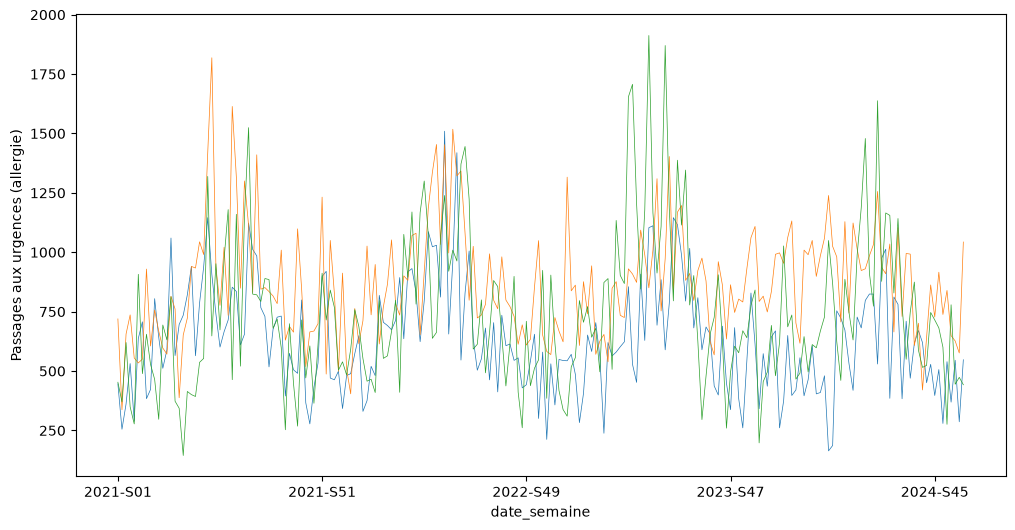

In [4]:
df.info()
print(df["TousAge_allergie_urgences"])
print(df["TousAge_allergie_urgences"].isna().sum())

#temp=df[df['code_dept']==68]
#plt.plot(temp["TousAge_allergie_urgences"])
#plt.plot(temp["TousAge_asthme_urgences"])

piv = df.pivot_table(index='date_semaine', columns='code_dept',
                     values='TousAge_allergie_urgences')

piv[['01','02','03']].plot(figsize=(12, 6), legend=False, linewidth=0.5)
plt.ylabel('Passages aux urgences (allergie)')
plt.show()

In [5]:
a_conserver = (list(range(8)) + list(range(10,14))+ list(range(20,31))+[36,39,45,50]+ list(range(57,60))+ list(range(61,68))+ list(range(69,76)))
df_mod=df.iloc[:,a_conserver]

print(df_mod.shape)             
print(df_mod.columns.tolist())   


(19968, 44)
['date_semaine', 'code_dept', 'As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'pression_mer', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'precipitation_24h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'TousAge_asthme_urgences', 'TousAge_allergie_hospitalisation', 'TousAge_asthme_hospitalisation', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologu

In [6]:
df_mod["code_dept"] = df_mod["code_dept"].astype(str)
df_mod["sos_present"] = df_mod["sos_present"].astype(int)
df_mod["annee"]   = df_mod["date_semaine"].str[:4].astype(int)
df_mod["semaine"] = df_mod["date_semaine"].str[-2:].astype(int)
df_mod = df_mod.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)

display(df_mod.head(5))
'''
y=X['TousAge_asthme_urgences']
X=pd.get_dummies(X, columns=['code_dept'], drop_first=True)
X = X.drop(columns=['sos_present','TousAge_asthme_urgences'])
'''

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,vent_vitesse,temperature_kelvin,...,pct_retraites,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee,semaine
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,1.875000,272.803571,...,26.0,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2021,1
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,2.982143,274.801786,...,26.0,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2021,2
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,5.125000,278.978571,...,26.0,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2021,3
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,2.517857,279.219643,...,26.0,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2021,4
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,3.732143,283.432143,...,26.0,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2021,5


"\ny=X['TousAge_asthme_urgences']\nX=pd.get_dummies(X, columns=['code_dept'], drop_first=True)\nX = X.drop(columns=['sos_present','TousAge_asthme_urgences'])\n"

In [7]:
print(df_mod.isna().sum())
somme_tp = df_mod.iloc[:, 13:22].sum(axis=1)
df_mod.iloc[:, 13:22] = df_mod.iloc[:, 13:22].div(somme_tp, axis=0)


date_semaine                                   0
code_dept                                      0
As in PM10                                     0
BaP in PM10                                    0
Cd in PM10                                     0
Ni in PM10                                     0
Pb in PM10                                     0
pression_mer                                   0
vent_vitesse                                   0
temperature_kelvin                             0
humidite_relative                              0
visibilite                                     0
precipitation_24h                              0
tp_averses_ou_orages                           0
tp_brouillard                                  0
tp_brume_fumee_ou_phenomenes_particuliers      0
tp_neige_precipitation_solide                  0
tp_phenomenes_recents_derniere_heure           0
tp_pluie_ou_bruine                             0
tp_sans_precipitation_visibilite_ou_nuages     0
tp_tempete_poussiere

In [8]:
df_temp=df_mod.copy()
g = df_temp.groupby("code_dept")["TousAge_allergie_urgences"]
df_temp["target"] = g.shift(-1)

df_temp = df_temp.dropna(subset=["target"]).reset_index(drop=True)
print(df_temp.shape)  

train = df_temp[df_temp["annee"] <= 2022]
val   = df_temp[df_temp["annee"] == 2023]
test  = df_temp[df_temp["annee"] == 2024]
print(len(train), len(val), len(test)) 

(19872, 47)
9984 4992 4896


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def scores(y_vrai, y_pred):
    """MAE, RMSE et R² dans un petit dictionnaire."""
    return {"MAE":  mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5,
            "R2":   r2_score(y_vrai, y_pred)}

print("Validation :", scores(val["target"],  val["TousAge_allergie_urgences"]))
print("Test       :", scores(test["target"], test["TousAge_allergie_urgences"]))

Validation : {'MAE': 219.17175531161257, 'RMSE': 306.61921009518534, 'R2': 0.10146037226869387}
Test       : {'MAE': 206.3886649817827, 'RMSE': 287.4353347957655, 'R2': 0.043364833431510874}


In [10]:
df_temp=df_mod.copy()
g = df_temp.groupby("code_dept")["TousAge_allergie_urgences"]
df_temp["target"] = g.shift(-1)
df_temp["TousAge_allergie_urgences_moy2"] = g.transform(lambda s: s.rolling(2).mean())

df_temp = df_temp.dropna(subset=["target", "TousAge_allergie_urgences_moy2"]).reset_index(drop=True)
print(df_temp.shape)  

train = df_temp[df_temp["annee"] <= 2022]
val   = df_temp[df_temp["annee"] == 2023]
test  = df_temp[df_temp["annee"] == 2024]
print(len(train), len(val), len(test)) 

(19776, 48)
9888 4992 4896


In [11]:
print("Validation :", scores(val["target"],  val["TousAge_allergie_urgences_moy2"]))
print("Test       :", scores(test["target"], test["TousAge_allergie_urgences_moy2"]))

Validation : {'MAE': 192.88978678209432, 'RMSE': 267.517494988019, 'R2': 0.31602080383697373}
Test       : {'MAE': 182.53272567277855, 'RMSE': 252.4709294774387, 'R2': 0.26194489469835247}


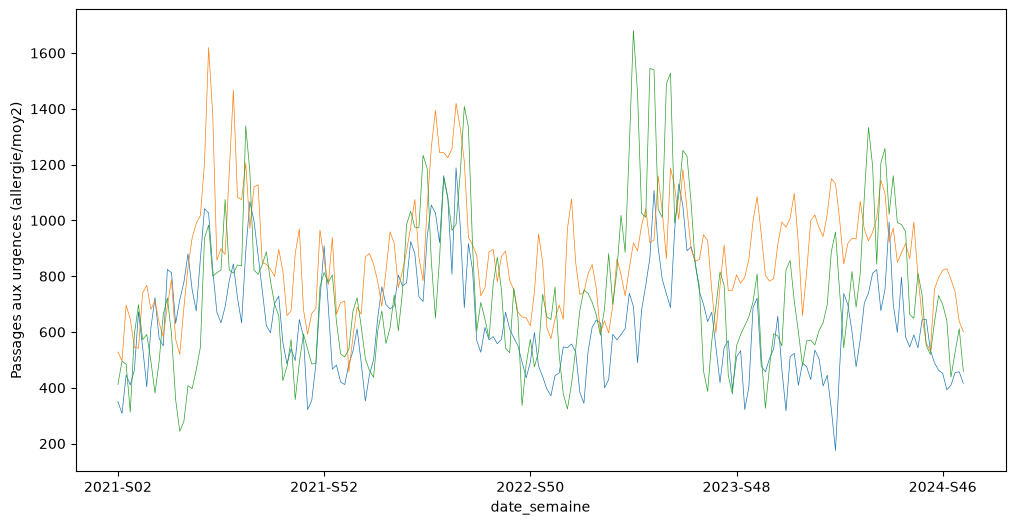

In [12]:
piv = df_temp.pivot_table(index='date_semaine', columns='code_dept',
                     values='TousAge_allergie_urgences_moy2')

piv[['01','02','03']].plot(figsize=(12, 6), legend=False, linewidth=0.5)
plt.ylabel('Passages aux urgences (allergie/moy2)')
plt.show()

In [13]:
df_temp = df_mod.copy()
g = df_temp.groupby("code_dept")["TousAge_allergie_urgences"]
df_temp["target"] = g.shift(-1)

moy2021_2022 = (df_temp[df_temp["annee"] <= 2022]
          .groupby(["code_dept", "semaine"])["TousAge_allergie_urgences"]
          .mean()
          .rename("TousAge_allergie_urgences_moy2021_2022")
          .reset_index())
display(moy2021_2022)

moy2021_2023 = (df_temp[df_temp["annee"] <= 2023]
          .groupby(["code_dept", "semaine"])["TousAge_allergie_urgences"]
          .mean()
          .rename("TousAge_allergie_urgences_moy2021_2023")
          .reset_index())
display(moy2021_2023)

# En test (2024), la semaine 52 n'a pas de target ; ce sont des lignes à retirer aussi des moyennes 2021-2023 :
moy2021_2023 = moy2021_2023[moy2021_2023["semaine"] != 52]

,code_dept,semaine,TousAge_allergie_urgences_moy2021_2022
0,01,1,458.315819
1,01,2,359.058424
2,01,3,430.301978
3,01,4,436.813608
4,01,5,385.187175
...,...,...,...
4987,95,48,806.901928
4988,95,49,751.539925
4989,95,50,688.019350
4990,95,51,920.820656


,code_dept,semaine,TousAge_allergie_urgences_moy2021_2023
0,01,1,498.780594
1,01,2,310.143691
2,01,3,463.666571
3,01,4,410.256691
4,01,5,439.726247
...,...,...,...
4987,95,48,810.435098
4988,95,49,832.046797
4989,95,50,777.913406
4990,95,51,942.073399


In [14]:
print("Validation :", scores(val["target"],  moy2021_2022["TousAge_allergie_urgences_moy2021_2022"]))
print("Test       :", scores(test["target"], moy2021_2023["TousAge_allergie_urgences_moy2021_2023"]))

Validation : {'MAE': 204.9752192337074, 'RMSE': 285.12256032851093, 'R2': 0.22303460065395964}
Test       : {'MAE': 194.6364558564793, 'RMSE': 266.26897280672125, 'R2': 0.1790680532464658}


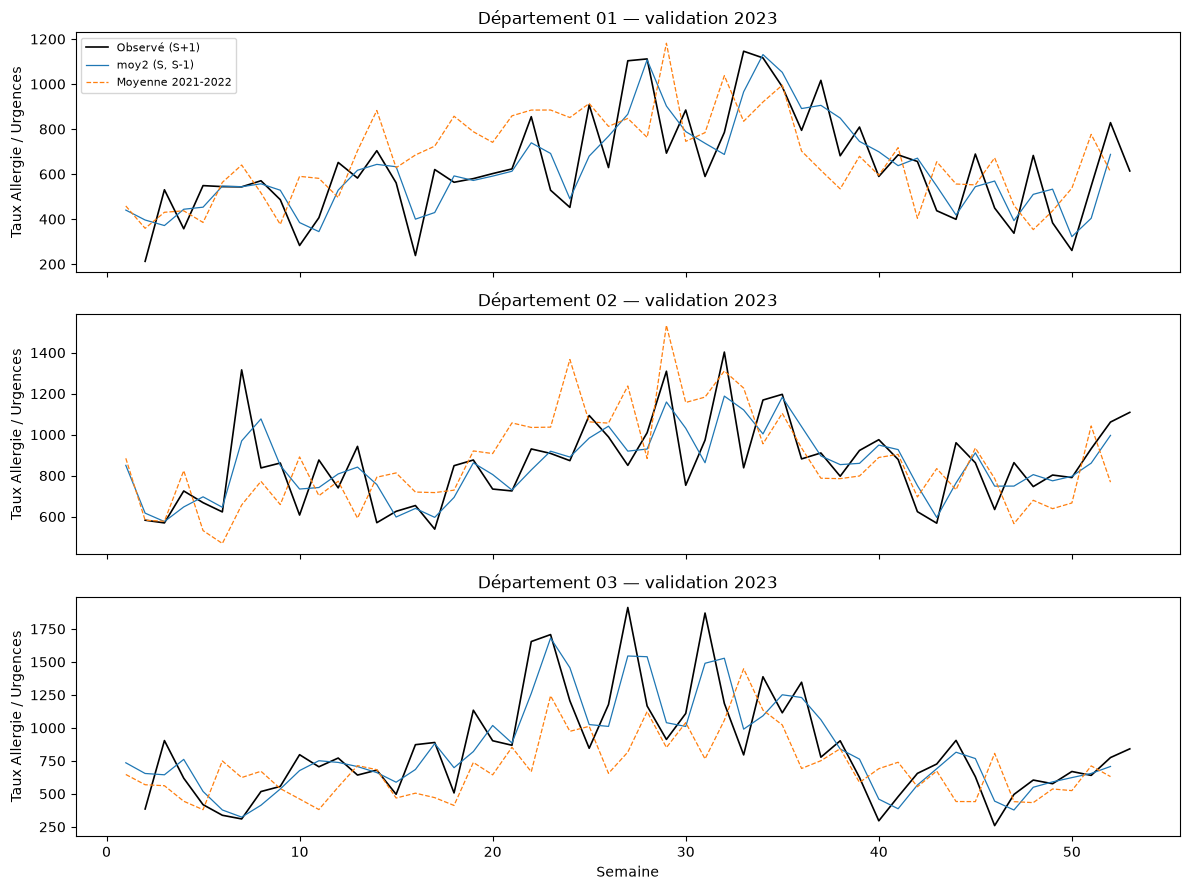

In [18]:
depts = ["01", "02", "03"]

# Une table de validation avec toutes les prédictions alignées par (département, semaine)
v = val.merge(moy2021_2022, on=["code_dept", "semaine"], how="left")

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, d in zip(axes, depts):
    s = v[v["code_dept"] == d]
    ax.plot(s["semaine"]+1, s["target"], color="black", linewidth=1.2, label="Observé (S+1)")
    #ax.plot(s["semaine"], s["TousAge_allergie_urgences"], linewidth=0.7, label="Persistance (S)")
    ax.plot(s["semaine"], s["TousAge_allergie_urgences_moy2"], linewidth=0.9, label="moy2 (S, S-1)")
    ax.plot(s["semaine"], s["TousAge_allergie_urgences_moy2021_2022"], linewidth=0.9,
            linestyle="--", label="Moyenne 2021-2022")
    ax.set_title(f"Département {d} — validation 2023")
    ax.set_ylabel("Taux Allergie / Urgences")
axes[0].legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Semaine")
plt.tight_layout()
plt.show()